# Air Temperature compression: KAN → residuals → ANS

This fixed proof-of-concept study evaluates a compact one-step predictor and ANS coding of signed residual ticks. It is not an ideal optimized or deployment model. The records remain chronological and are split 70/20/10 before training-only imputation and window creation. Training alone determines source quantum, model parameters, residual support, and ANS frequencies. Validation evaluates the predictor and primary full-suffix codec roundtrip.

Historical provenance: a 256-value test-prefix check was disclosed previously; it is not rerun here and is not a pristine full-test result.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pathlib import Path
from time import perf_counter
from decimal import Decimal
from kan.MultKAN import KAN
import sys
_repo_candidates = [Path.cwd(), Path.cwd().parent, (Path.cwd() / 'datasets').resolve().parent]
_repo_root = next((p.resolve() for p in _repo_candidates if (p / 'compression_evaluation').is_dir()), None)
if _repo_root is None:
    raise RuntimeError('Could not locate repository compression_evaluation package')
sys.path.insert(0, str(_repo_root))
import compression_evaluation.types as util_types
from compression_evaluation.poc import (chronological_bounds, impute_training_only, infer_decimal_quantum, make_windows, checked_ticks, snap_to_grid, SignedGridQuantizer, fit_training_alphabet, make_codec_pair, evaluate_suffix, benchmark_pairs, pinned_allowed_cpu)
import compression_evaluation.methods as util_methods
import compression_evaluation.classes as util_classes
import compression_evaluation.types as util_types
from compression_evaluation.poc_plots import plot_training_series, plot_training_distribution, plot_residual_counts


## 1. Load and check the series

The CSV is read as a sequence, not as a table to be chronologically “fixed.” Duplicate timestamps and the recorded backward timestamp step are part of the observed dataset. Sorting would silently change which measurements are adjacent and thus change both the prediction task and the residual stream. We retain the original decimal strings alongside numeric values: floating-point parsing is convenient for learning, while the strings let the later source-grid estimate reflect the precision actually written in the training records.

### Load the recorded series

The path check locates the Air Temperature CSV. Timestamp and row checks confirm which observations are present without changing their order.

In [2]:
# Resolve the tracked dataset from either repository-root or notebooks/ cwd.
candidates = [
    Path.cwd() / 'datasets/AriviyalN_Data_Air_Temperature.csv',
    Path.cwd().parent / 'datasets/AriviyalN_Data_Air_Temperature.csv',
]
csv_path = next((path for path in candidates if path.is_file()), None)
if csv_path is None:
    raise FileNotFoundError(
        'Air Temperature CSV not found; expected datasets/AriviyalN_Data_Air_Temperature.csv '
        'from repository root or notebooks/.'
    )


In [3]:
air_temperature_df = pd.read_csv(csv_path, dtype={'Air Temperature': 'string'})
required_columns = {'Timestamp', 'Air Temperature'}
missing_columns = required_columns.difference(air_temperature_df.columns)
if missing_columns:
    raise ValueError(f'Missing required headers: {sorted(missing_columns)}')
air_temperature_df['Timestamp'] = pd.to_datetime(
    air_temperature_df['Timestamp'], dayfirst=True, errors='coerce'
)
if air_temperature_df['Timestamp'].isna().any():
    invalid_count = int(air_temperature_df['Timestamp'].isna().sum())
    raise ValueError(f'Invalid Timestamp values: {invalid_count}')
backwards = int((air_temperature_df['Timestamp'].diff() < pd.Timedelta(0)).sum())
duplicates = int(air_temperature_df['Timestamp'].duplicated().sum())
if len(air_temperature_df) != 51354 or backwards != 1 or duplicates != 192:
    raise ValueError(
        f'Unexpected timestamp/data drift: rows={len(air_temperature_df)}, '
        f'backwards adjacent steps={backwards}, duplicate timestamps={duplicates}.'
    )
print(
    'Rows:', len(air_temperature_df),
    'duplicate timestamps:', duplicates,
    'backwards adjacent steps:', backwards,
)
# Preserve the observed backward step and duplicates; never reorder the source.

Rows: 51354 duplicate timestamps: 192 backwards adjacent steps: 1


### Preserve decimal precision

Numeric values support modeling, while the original decimal strings support exact inference of the source lattice. The lattice is inferred later from training rows only.

In [4]:
# Parse numeric values while retaining original decimal text for training-grid inference.
air_temperature_text = air_temperature_df['Air Temperature'].reset_index(drop=True)
air_temperature_column = pd.to_numeric(air_temperature_text, errors='coerce')



## 2. Split chronologically and inspect training data

The split is positional: the earliest 70% is training, the next 20% validation, and the final 10% test. This ordering mimics forecasting into later observations and avoids allowing future values to inform training. The split happens before handling missing values or forming windows. The one missing record lies in training and is forward-filled only from the preceding finite training observation. Validation and test values are not imputed. Creating windows separately inside each partition also prevents an input window from borrowing records across a boundary.

### Set chronological boundaries

The 70/20/10 boundaries are positional and precede imputation. Only the missing training observation is filled from an earlier finite training value.

In [5]:
n = len(air_temperature_column)
train_end, val_end = chronological_bounds(n)
if (n, train_end, val_end) != (51354, 35947, 46218):
    raise ValueError(f'Unexpected dataset shape/boundaries: {n}, {train_end}, {val_end}')
raw_values = air_temperature_column.to_numpy(dtype=np.float64)
missing_positions = np.flatnonzero(np.isnan(raw_values))
if missing_positions.tolist() != [34567]:
    raise ValueError(f'Unexpected missing training observation positions: {missing_positions.tolist()}')
print('Missing training observation index:', missing_positions.tolist())
raw_values = impute_training_only(raw_values, train_end, val_end)


Missing training observation index: [34567]


### Infer training source precision

The decimal quantum is inferred from training text only. This keeps validation and test values from determining the precision used by the codec.

In [6]:
train_values = raw_values[:train_end].copy()
step = float(infer_decimal_quantum(air_temperature_text.iloc[:train_end]))
if not np.isfinite(step) or step <= 0:
    raise ValueError(f'Invalid inferred training data quantum: {step}')
print('Training-inferred decimal quantum:', step)
val_values = raw_values[train_end:val_end].copy()
test_values = raw_values[val_end:].copy()


Training-inferred decimal quantum: 0.1


Training-partition time series (exploratory plot).

### Inspect training observations

The sequence plot exposes temporal variation and unusual local behavior in row order.

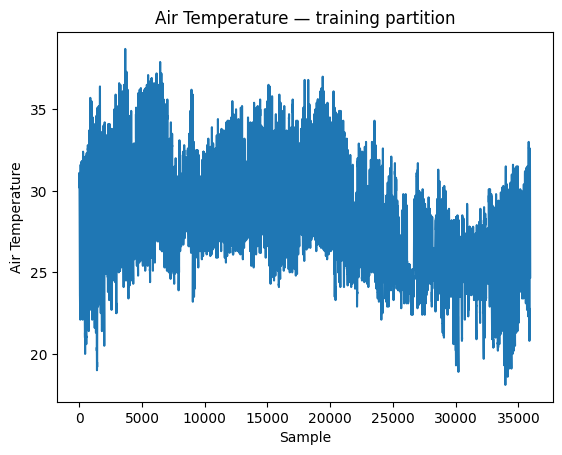

In [7]:
fig = plot_training_series(train_values)
ax = fig.axes[0]
ax.set_title('Air Temperature — training partition')
ax.set_ylabel('Air Temperature')
plt.show()

### Inspect the value distribution

The histogram shows how frequently training values occur at each level.

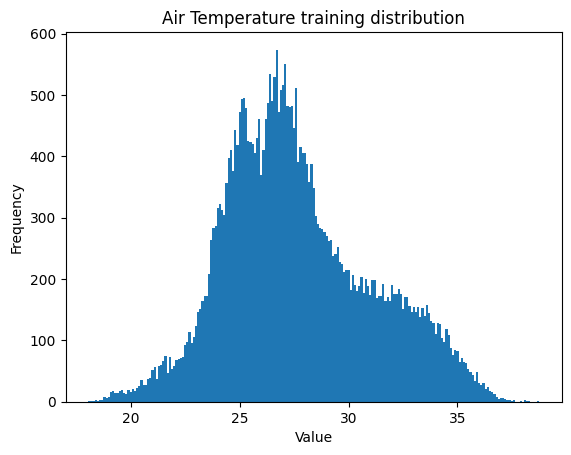

In [8]:
fig = plot_training_distribution(train_values, step)
ax = fig.axes[0]
ax.set_title('Air Temperature training distribution')
plt.show()

### Verify partition sizes

These boundaries confirm the chronological sample counts before any windows are formed.

In [9]:
# Confirm the chronological boundaries before constructing any windows.
print('Train:', (0, train_end))
print('Validation:', (train_end, val_end))
print('Test:', (val_end, n))

Train: (0, 35947)
Validation: (35947, 46218)
Test: (46218, 51354)


## 3. Train the fixed KAN predictor

The prediction task is deliberately local and explicit: eight preceding observations are the context, and the next observed value is the target. A context made from observed values measures one-step forecasting; the codec, by contrast, must advance using its own reconstructed values after the initial context. That distinction matters because small prediction errors can change later contexts in a closed loop.

The predictor is fixed rather than searched: KAN width `[8, 1]`, grid 5, spline order `k=3`, seed 42, float64, and 50 LBFGS steps (batch 256). Training windows update the model. Validation is passed to pyKAN's validation-monitoring fields, historically named `test_input` and `test_label`; it monitors fit but is not the held-out final test set and does not update the model. The model is not automatically saved.

### Construct one-step windows

Each example contains eight preceding observations and the following target. Keeping windows within their partition prevents leakage across split boundaries.

In [10]:
X_train, y_train = make_windows(train_values)
X_valid, y_valid = make_windows(val_values)

# Shuffle training window order reproducibly; retain input/target pairs.
order = np.random.default_rng(42).permutation(len(X_train))
X_train = X_train[order]
y_train = y_train[order]


### Prepare the fixed model

Inputs and targets use float64 tensors. In pyKAN, `test_input` and `test_label` name the validation monitoring data; they are not the held-out final test partition.

In [11]:
# Float64 is used consistently for this small, fixed predictor.
torch.set_default_dtype(torch.float64)
training_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
inference_device = torch.device('cpu')
print('Training device:', training_device, '| post-fit inference device:', inference_device)

X_train_t = torch.as_tensor(X_train, dtype=torch.float64, device=training_device)
y_train_t = torch.as_tensor(y_train, dtype=torch.float64, device=training_device)
X_valid_t = torch.as_tensor(X_valid, dtype=torch.float64, device=training_device)
y_valid_t = torch.as_tensor(y_valid, dtype=torch.float64, device=training_device)
# pyKAN calls the validation fields test_input/test_label; fit uses them only
# to monitor validation loss, not to update model parameters.
dataset = {
    'train_input': X_train_t,
    'train_label': y_train_t,
    'test_input': X_valid_t,
    'test_label': y_valid_t,
}
model_config = {
    'width': [8, 1],
    'grid': 5,
    'k': 3,
    'seed': 42,
    'opt': 'LBFGS',
    'steps': 50,
    'batch': 256,
    'lamb': 0.0,
    'dtype': 'float64',
    'auto_save': False,
}
kan_model = KAN(
    width=[8, 1],
    grid=5,
    k=3,
    seed=42,
    device=training_device,
    auto_save=False,
).double()



Training device: cuda | post-fit inference device: cpu


### Fit and monitor validation loss

The model is fitted on training windows. pyKAN labels its validation loss `test_loss`; here that value monitors validation only.

In [12]:
# Fit on training windows; pyKAN's separate validation fields only monitor loss.
fit_start = perf_counter()
kan_model.fit(dataset, opt='LBFGS', steps=50, batch=256, lamb=0.0)
if training_device.type == 'cuda':
    torch.cuda.synchronize()
fit_elapsed_seconds = perf_counter() - fit_start
# All post-fit inference and reported codec runs are CPU-only.
kan_model = kan_model.to(inference_device)
kan_model.eval()
kan_model.auto_save = False
X_train_t = X_train_t.to(inference_device)
y_train_t = y_train_t.to(inference_device)
X_valid_t = X_valid_t.to(inference_device)
y_valid_t = y_valid_t.to(inference_device)
assert all(t.device.type == 'cpu' for t in (X_train_t, y_train_t, X_valid_t, y_valid_t))
assert all(t.device.type == 'cpu' for t in list(kan_model.parameters()) + list(kan_model.buffers()))
with torch.no_grad():
    y_train_pred = kan_model(X_train_t)
    y_valid_pred = kan_model(X_valid_t)



description:   0%|                                                           | 0/50 [00:00<?, ?it/s]

| train_loss: 2.50e-01 | test_loss: 2.60e-01 | reg: 0.00e+00 | :   0%|       | 0/50 [00:01<?, ?it/s]

| train_loss: 2.50e-01 | test_loss: 2.60e-01 | reg: 0.00e+00 | :   2%| | 1/50 [00:01<00:56,  1.15s/i

| train_loss: 3.27e-01 | test_loss: 2.35e-01 | reg: 0.00e+00 | :   2%| | 1/50 [00:01<00:56,  1.15s/i

| train_loss: 3.27e-01 | test_loss: 2.35e-01 | reg: 0.00e+00 | :   4%| | 2/50 [00:01<00:26,  1.81it/

...

| train_loss: 2.25e-01 | test_loss: 4.15e-01 | reg: 0.00e+00 | :  96%|▉| 48/50 [00:07<00:00,  7.59it

| train_loss: 2.25e-01 | test_loss: 4.15e-01 | reg: 0.00e+00 | :  98%|▉| 49/50 [00:07<00:00,  7.56it

| train_loss: 2.18e-01 | test_loss: 3.32e-01 | reg: 6.74e+00 | :  98%|▉| 49/50 [00:07<00:00,  7.56it

| train_loss: 2.18e-01 | test_loss: 3.32e-01 | reg: 6.74e+00 | : 100%|█| 50/50 [00:07<00:00,  6.17it

| train_loss: 2.18e-01 | test_loss: 3.32e-01 | reg: 6.74e+00 | : 100%|█| 50/50 [00:07<00:00,  6.52it

These are conventional one-step prediction errors computed from raw, unsnapped KAN outputs. Mean absolute error (MAE) describes typical absolute deviation; mean squared error (MSE) penalizes larger deviations more strongly. Because these numbers use observed-context windows, they assess the predictor before any residual coding and are not codec reconstruction metrics. The later codec snaps predictions to the inferred source lattice, so its reconstruction errors are reported separately.

In [13]:
train_error = y_train_t - y_train_pred
validation_error = y_valid_t - y_valid_pred
train_mae = float(torch.mean(torch.abs(train_error)).item())
train_mse = float(torch.mean(train_error ** 2).item())
validation_mae = float(torch.mean(torch.abs(validation_error)).item())
validation_mse = float(torch.mean(validation_error ** 2).item())



### Check prediction-cache parity

Disabling activation caching is a memory setting; predictions on the probe rows are checked before and after.

In [14]:
# Turn off cached activation recording after fitting and raw metrics. Check
# that this memory-saving setting leaves predictions unchanged on two rows.
with torch.no_grad():
    parity_input = X_valid_t[:2]
    prediction_before = kan_model(parity_input).detach().clone()
kan_model.save_act = False
with torch.no_grad():
    prediction_after = kan_model(parity_input).detach().clone()
if not torch.isfinite(prediction_before).all() or not torch.isfinite(prediction_after).all():
    raise AssertionError('KAN parity predictions must be finite')
if not torch.equal(prediction_before, prediction_after):
    raise AssertionError('Disabling activation caching changed KAN predictions')



### Compare persistence baseline

Persistence is a deliberately simple baseline: predict the next value by repeating the last value in the eight-sample context. It needs no fitted parameters and is often difficult to beat for slowly changing series. Evaluating it on exactly the same train and validation windows makes the comparison interpretable. The strict gate below requires the KAN to improve both validation MAE and MSE; otherwise the notebook stops before presenting a codec result, avoiding a compression narrative built on an inferior forecast.

In [15]:
# Persistence predicts the final observed value in each same-partition window.
# Compute it on both the shuffled training pairs and validation pairs.
persistence_train_pred = X_train[:, -1, None]
persistence_train_error = y_train - persistence_train_pred
persistence_train_mae = float(np.mean(np.abs(persistence_train_error)))
persistence_train_mse = float(np.mean(persistence_train_error ** 2))
persistence_valid_pred = X_valid[:, -1, None]
persistence_error = y_valid - persistence_valid_pred
persistence_mae = float(np.mean(np.abs(persistence_error)))
persistence_mse = float(np.mean(persistence_error ** 2))



### Review the metric table

KAN and persistence results are shown separately for train and validation.

In [16]:
metric_table = pd.DataFrame(
    [
        {'split': 'Train', 'predictor': 'KAN', 'MAE': train_mae, 'MSE': train_mse},
        {
            'split': 'Train',
            'predictor': 'Persistence',
            'MAE': persistence_train_mae,
            'MSE': persistence_train_mse,
        },
        {
            'split': 'Validation',
            'predictor': 'KAN',
            'MAE': validation_mae,
            'MSE': validation_mse,
        },
        {
            'split': 'Validation',
            'predictor': 'Persistence',
            'MAE': persistence_mae,
            'MSE': persistence_mse,
        },
    ]
)
print('Model config:', model_config)
print(f'Fit time: {fit_elapsed_seconds:.2f} seconds')
display(metric_table)



Model config: {'width': [8, 1], 'grid': 5, 'k': 3, 'seed': 42, 'opt': 'LBFGS', 'steps': 50, 'batch': 256, 'lamb': 0.0, 'dtype': 'float64', 'auto_save': False}
Fit time: 7.72 seconds


,split,predictor,MAE,MSE
0,Train,KAN,0.178038,0.088375
1,Train,Persistence,0.215535,0.114848
2,Validation,KAN,0.176256,0.092067
3,Validation,Persistence,0.215834,0.121359


### Apply the validation quality gate

Codec evaluation proceeds only when KAN improves both validation MAE and MSE over persistence.

In [17]:
# Do not build a residual codec if either validation error is not improved.
quality_gate_passed = (
    validation_mae < persistence_mae and validation_mse < persistence_mse
)
if not quality_gate_passed:
    raise RuntimeError(
        'KAN quality gate failed: both validation MAE and MSE must be strictly '
        'lower than persistence before codec evaluation.'
    )
print('Quality gate passed: KAN improves both validation MAE and MSE.')

Quality gate passed: KAN improves both validation MAE and MSE.


## 4. Define and inspect training residuals

The predictor and codec serve different roles. One-step MAE/MSE characterize the raw model. For coding, the prediction is rounded onto a decimal lattice inferred from training records, making the difference between a lattice-valued observation and its prediction an integer number of ticks. That signed residual is what the entropy coder encodes. Rounding applies only to codec predictions; it does not revise the model metrics or alter source observations.

### Define signed grid ticks

A tick is an integer multiple of the training-inferred quantum. The residual sign is retained; the nonnegative ANS index is introduced separately.

### Snap codec predictions to the lattice

Rounding the predictor output to the source lattice lets a target on that lattice produce an integer signed residual tick.

### Check lattice and signed arithmetic

Small deterministic examples verify decimal-quantum inference and positive and negative tick conversion.

In [18]:
# Deterministic decimal-grid and signed-tick sanity checks.
assert infer_decimal_quantum(['0.10', '-0.20', '0.30']) == Decimal('0.10')
assert infer_decimal_quantum(['0.05', '-0.10', '0.15']) == Decimal('0.05')
assert checked_ticks([-0.2, 0.0, 0.3], 0.1, 'synthetic .1 grid').tolist() == [-2, 0, 3]
assert checked_ticks([-0.1, 0.05], 0.05, 'synthetic .05 grid').tolist() == [-2, 1]



For each shuffled training window, subtract the snapped prediction tick from the target tick. The resulting residual is signed: positive means the observed target is above prediction, negative means it is below. We then find the minimum and maximum training residual ticks and pad both ends by five ticks. This fixed, training-derived support provides room for modest unseen errors without learning support from validation or test. The count histogram has one position per signed tick; it is the empirical distribution used to construct the entropy model.

In [19]:
alphabet = fit_training_alphabet(y_train_t.detach().cpu().numpy(), y_train_pred.detach().cpu().numpy(), step, pad_ticks=5, total_frequency=1024)
quantizer = alphabet.quantizer
low, high, levels = alphabet.low_tick, alphabet.high_tick, alphabet.quantizer.levels
counts, frequencies = alphabet.counts, list(alphabet.frequencies)
train_target_ticks = checked_ticks(y_train_t.detach().cpu().numpy(), step, 'training targets')
train_prediction_ticks = checked_ticks(snap_to_grid(y_train_pred.detach().cpu().numpy(), step), step, 'snapped training predictions')
residual_ticks = train_target_ticks - train_prediction_ticks
train_residuals = residual_ticks.astype(np.float64) * step
ans_indices = residual_ticks - low
if np.any(ans_indices < 0) or np.any(ans_indices >= levels): raise AssertionError('Residual indices outside padded training alphabet')
if int(counts.sum()) != residual_ticks.size: raise AssertionError('Residual histogram count mismatch')
print('Training signed residual ticks:', residual_ticks.size, 'alphabet levels:', levels)


Training signed residual ticks: 35939 alphabet levels: 101


### View signed residual frequencies

The horizontal positions are signed physical residual values; bar heights are training counts.

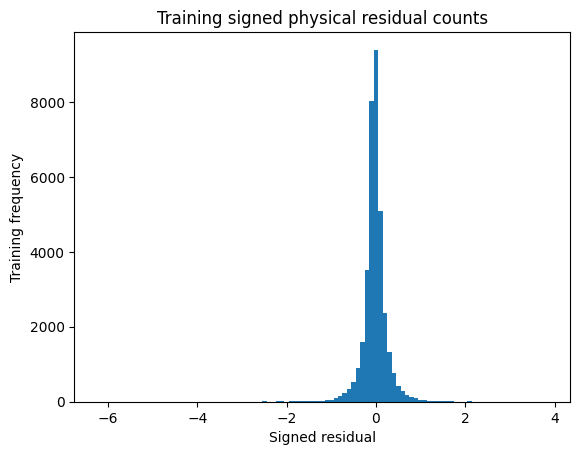

In [20]:
fig = plot_residual_counts(alphabet, step)
ax = fig.axes[0]
ax.set_title('Training signed physical residual counts')
plt.show()

## 5. Quantize symbols and build the ANS coder

ANS requires a positive integer frequency for each supported symbol, with all frequencies summing to a fixed total of 1024. Adding one to each training count supplies nonzero mass even for padded or otherwise unseen bins; largest-remainder normalization converts those weights to the required total while preserving their relative proportions as closely as possible. These frequencies are learned from training residuals only. They are model state needed by a real decoder and are excluded from the payload-only evaluator sizes below.

In [21]:
if len(frequencies) != levels or any(frequency <= 0 for frequency in frequencies):
    raise AssertionError('Every symbol needs a positive normalized frequency')
if sum(frequencies) != 1024:
    raise AssertionError('ANS frequencies must sum to 1024')


ANS implementations use zero-based nonnegative symbol identifiers, whereas residual ticks can be negative. We translate a signed tick `r` to the array index `r - low`, where `low` is the signed lower edge of the training support. This is an indexing translation only: decoding that index restores the same signed tick and physical residual `(low + index) × quantum`. In particular, zero-based ANS numbering does not shift the physical residual distribution.

### Check quantizer boundaries

Every supported signed residual maps to a valid zero-based symbol and back. Off-grid and out-of-support values are rejected.

In [22]:
quantizer = SignedGridQuantizer(step, low, high)
if quantizer.levels != levels:
    raise ValueError('Training quantizer bounds mismatch')
# Boundary and invalid-input checks for signed physical values and ANS indices.
assert quantizer.symbol_to_value(0) == low * step
assert quantizer.symbol_to_value(levels - 1) == high * step
assert quantizer.value_to_symbol(low * step) == 0
assert quantizer.value_to_symbol(high * step) == levels - 1
for invalid_value in ((low - 1) * step, (high + 1) * step, 0.0137):
    try:
        quantizer.value_to_symbol(invalid_value)
    except ValueError:
        pass
    else:
        raise AssertionError(f'Invalid residual unexpectedly accepted: {invalid_value}')
for invalid_symbol in (-1, levels):
    try:
        quantizer.symbol_to_value(invalid_symbol)
    except ValueError:
        pass
    else:
        raise AssertionError(f'Invalid symbol unexpectedly accepted: {invalid_symbol}')

for symbol in range(levels):
    restored_symbol = quantizer.value_to_symbol(quantizer.symbol_to_value(symbol))
    if restored_symbol != symbol:
        raise AssertionError(f'Quantizer symbol roundtrip failed for {symbol}')


### Build the ANS frequency table

The coder receives the normalized positive frequencies and the signed-grid quantizer.

In [23]:
frequency_table = util_classes.SimpleFrequencyTable(frequencies)
ans_coder = util_classes.ANSCoder(frequency_table, quantizer)



### Verify lossless ANS symbol coding

A deterministic training-derived probe checks that symbol indices survive encode/decode exactly.

In [24]:
probe_symbols = np.concatenate(
    [np.arange(levels), ans_indices.ravel()[:min(256, ans_indices.size)]]
)
ans_bytes = ans_coder.encode_symbols(probe_symbols.tolist())
if ans_coder.decode_symbols(ans_bytes) != probe_symbols.tolist():
    raise AssertionError('ANS symbol roundtrip failed')
print('ANS lossless symbol roundtrip passed; probe bytes:', len(ans_bytes))


ANS lossless symbol roundtrip passed; probe bytes: 224


### Synthetic .05-grid codec check

This separate small example exercises signed residuals and ANS mechanics on a .05 lattice; it is not a model result.

In [25]:
synthetic_q = SignedGridQuantizer(0.05, -3, 3)
synthetic_freq = util_methods.largest_remainder_quantize([1] * 7, 1024)
synthetic_coder = util_classes.ANSCoder(
    util_classes.SimpleFrequencyTable(synthetic_freq), synthetic_q
)
prediction_ticks = np.array([0, 1, -1], dtype=np.int64)
target_ticks = np.array([1, -1, 0], dtype=np.int64)
synthetic_residual_ticks = target_ticks - prediction_ticks
synthetic_values = synthetic_residual_ticks.astype(np.float64) * 0.05
synthetic_indices = [synthetic_q.value_to_symbol(value) for value in synthetic_values]
synthetic_payload = synthetic_coder.encode_symbols(synthetic_indices)
synthetic_decoded = synthetic_coder.decode_symbols(synthetic_payload)
assert synthetic_decoded == synthetic_indices
restored_ticks = np.array(
    [round(synthetic_q.symbol_to_value(index) / 0.05) for index in synthetic_decoded],
    dtype=np.int64,
)
assert np.array_equal(restored_ticks, synthetic_residual_ticks)
try:
    synthetic_q.value_to_symbol(0.03)
except ValueError:
    pass
else:
    raise AssertionError('Off-grid .05 residual was unexpectedly accepted')
try:
    synthetic_q.value_to_symbol(-4 * 0.05)
except ValueError:
    pass
else:
    raise AssertionError('Off-support .05 residual was unexpectedly accepted')
print('Synthetic .05 signed residual ANS roundtrip passed')

Synthetic .05 signed residual ANS roundtrip passed


## 6. Assemble encoder and decoder

The encoder and decoder each need the same fitted predictor, quantizer, and normalized frequency table. These are shared read-only study state—not transmitted inside the measured payload. Each side separately owns an eight-value rolling history. The validation run begins with the first eight observed validation values as a bootstrap; each later source value is coded as a residual against the encoder's predicted next value. The decoder decodes that residual and adds it to its own prediction, then advances its own history with the reconstruction. Consequently, after bootstrap the predictor sees reconstructed history, not the original observed context.

This is a closed-loop residual codec. A roundtrip succeeds only if both sides keep synchronized histories, so the notebook checks that their final windows agree. The first eight values are external bootstrap information. For a transparent size estimate, their float64 representation is counted as 8 × 8 = 64 bytes, while model weights, frequency table, quantizer, and framing/metadata are excluded. This is therefore not a complete deployable-file size.

### Create independent codec histories

Each factory call creates a fresh encoder and decoder with separate copies of the observed eight-value bootstrap.

In [26]:
def numeric_predictor(X):
    X = np.asarray(X, dtype=np.float64)
    if X.shape != (1, 8): raise ValueError('predictor expects one eight-value row')
    tensor = torch.as_tensor(X, dtype=torch.float64, device='cpu')
    with torch.no_grad():
        output = kan_model(tensor).detach().cpu().numpy().reshape(1, 1)
    assert output.shape == (1, 1) and np.isfinite(output).all()
    return output
assert next(kan_model.parameters()).device.type == 'cpu'


## 7. Full-validation prediction-residual and compression study

This is the single primary validation codec pass. The first eight validation observations initialize two independent rolling histories; every remaining observation is coded once. The predictor receives reconstructed history in closed loop, so the residual stream is not equivalent to residuals computed against a sequence of original observed contexts.

The main questions are predictive quality (raw KAN versus persistence MAE/MSE), the closed-loop residual-symbol distribution, and actual full-validation payload size. Shannon entropy and cross-entropy are distributional reference quantities, not promises about finite ANS payload length. The training frequency table is fixed before validation and validation never changes its support.


### Measure one evaluator roundtrip without retaining payload or reconstruction

`Evaluator` calls each adapter once. The encoder-only counting quantizer observes the signed symbols as they are emitted, without retaining the payload. The decoder receives the original quantizer and has no access to validation source values. A separate evaluator-facing guard checks the decoded sequence against source-grid ticks, then returns the decoder output unchanged. Thus evaluator MSE/SNR remain measurements of the real reconstruction. Predictor histories are independently updated and checked for synchronization.


In [27]:
validation_bootstrap = np.asarray(val_values[:8], dtype=np.float64).copy()
validation_suffix = np.asarray(val_values[8:], dtype=np.float64)
if len(val_values) != 10271 or len(validation_suffix) != 10263: raise AssertionError('Unexpected validation/bootstrap/coded counts')
validation_study = evaluate_suffix(val_values, numeric_predictor, alphabet, step, input_size=8)
full_validation_metrics = validation_study.metrics
validation_symbols, validation_counts = validation_study.symbols, validation_study.counts
validation_entropy, validation_cross_entropy, validation_mismatch_gap = validation_study.entropy_bits, validation_study.cross_entropy_bits, validation_study.mismatch_gap_bits
zero_fraction, plus_one_fraction, minus_one_fraction = validation_study.zero_fraction, validation_study.plus_one_fraction, validation_study.minus_one_fraction
mean_abs_residual, payload_bytes = validation_study.mean_abs_residual, full_validation_metrics['compressed_size_bytes']
payload_ratio, actual_bps = full_validation_metrics['compression_ratio'], full_validation_metrics['bits_per_symbol']
bootstrap_bytes, bootstrap_ratio, bootstrap_bpv = validation_study.bootstrap_bytes, validation_study.bootstrap_ratio, validation_study.bootstrap_bits_per_value
low, high, levels = alphabet.low_tick, alphabet.high_tick, alphabet.quantizer.levels
print('PRIMARY: one full-validation Evaluator pass; payload bytes exclude bootstrap/model/table metadata.')
print(f'Payload: {payload_bytes} bytes; compression ratio: {payload_ratio:.6f}x; actual ANS rate: {actual_bps:.6f} bits/coded symbol')
print(f'Bootstrap-inclusive estimate (8 values / 64 bytes added): ratio={bootstrap_ratio:.6f}x; {bootstrap_bpv:.6f} bits/value; excludes model, table, quantizer and framing')
print(f'Validation empirical H(q)={validation_entropy:.6f} bits/symbol; cross-entropy against fixed training p={validation_cross_entropy:.6f}; mismatch gap={validation_mismatch_gap:.6f} bits/symbol')
print(f'Residual frequencies: zero={zero_fraction:.6%}, +1 tick={plus_one_fraction:.6%}, -1 tick={minus_one_fraction:.6%}; mean |residual|={mean_abs_residual:.8g} physical units')
print(f'Occupied validation bins={int(np.count_nonzero(validation_counts))}/{levels}; fixed support ticks=[{low},{high}]')
print(f'Evaluator reconstruction: MSE={full_validation_metrics["mse"]:.12g}, SNR={full_validation_metrics["snr_db"]:.6g} dB; exact source-grid ticks checked.')
print('Finite-stream ANS bits/symbol is measured, not required to exceed empirical entropy.')


PRIMARY: one full-validation Evaluator pass; payload bytes exclude bootstrap/model/table metadata.
Payload: 4251 bytes; compression ratio: 19.314044x; actual ANS rate: 3.313651 bits/coded symbol
Bootstrap-inclusive estimate (8 values / 64 bytes added): ratio=19.042410x; 3.360919 bits/value; excludes model, table, quantizer and framing
Validation empirical H(q)=3.207668 bits/symbol; cross-entropy against fixed training p=3.312793; mismatch gap=0.105125 bits/symbol
Residual frequencies: zero=25.703985%, +1 tick=14.459710%, -1 tick=22.732145%; mean |residual|=0.17399396 physical units
Occupied validation bins=58/101; fixed support ticks=[-62,38]
Evaluator reconstruction: MSE=5.86876233416e-30, SNR=321.333 dB; exact source-grid ticks checked.
Finite-stream ANS bits/symbol is measured, not required to exceed empirical entropy.


## 8. Exploratory symbolic optimization (training-only)

This is a separate, exploratory attempt to replace the fitted numeric edge functions with a compact formula from a fixed library. The optimizer sees only 256 deterministic training contexts; validation is used only to check equivalence and measure the already-declared prediction/compression criteria. It operates on a deep copy, leaving the trained numeric predictor and its primary result untouched. A formula is considered usable only if the exported SymPy/lambdified expression agrees numerically with pyKAN’s symbolic forward pass on the fitting subset and the full validation inputs, including identical snapped ticks. This is not final-model selection and does not trigger any test-set evaluation.

Each symbolic edge computes `mask * (c * f(a*x+b) + d)`. The cell reconstructs the complete one-layer output, including pyKAN’s subnode and node affine scales, directly from full-precision fitted parameters. The single predeclared candidate library is `x, x^2, x^3, sin, cos, tanh`. The 180-second timer bounds fitting; timeout or an ordinary fitting/parity/codec failure is reported explicitly as an incomplete attempt, without invalidating the numeric section.


In [28]:
import copy, signal, sympy as sp

_symbolic_outcome = 'attempt did not complete: not started'
_symbolic_metrics = None
_symbolic_valid_pred = None
_symbolic_callable = None
_symbolic_metrics = None
_symbolic_edge_names = []
_symbolic_fit_elapsed = None
_symbolic_callable = None

def _symbolic_alarm(_signum, _frame):
    raise TimeoutError('symbolic fitting exceeded 180 seconds')

try:
    _symbolic_probe_idx = np.linspace(0, len(X_train_t) - 1, 256, dtype=int)
    _symbolic_train = X_train_t[_symbolic_probe_idx].detach().clone()
    _symbolic_original_probe = kan_model(_symbolic_train).detach().clone()
    _symbolic_original_state = {k: v.detach().clone() for k, v in kan_model.state_dict().items()}
    symbolic_model = copy.deepcopy(kan_model)
    _old_handler = signal.getsignal(signal.SIGALRM)
    _old_timer = signal.getitimer(signal.ITIMER_REAL)
    if _old_timer[0] > 0:
        raise RuntimeError(f'pre-existing ITIMER_REAL is active ({_old_timer[0]:.3f}s remaining); symbolic timer not installed')
    _fit_start = perf_counter()
    try:
        signal.signal(signal.SIGALRM, _symbolic_alarm)
        signal.setitimer(signal.ITIMER_REAL, 180)
        symbolic_model.save_act = True
        with torch.no_grad():
            symbolic_model(_symbolic_train)
        symbolic_model.auto_symbolic(lib=['x', 'x^2', 'x^3', 'sin', 'cos', 'tanh'], verbose=0)
    finally:
        signal.setitimer(signal.ITIMER_REAL, 0)
        signal.signal(signal.SIGALRM, _old_handler)
        _symbolic_fit_elapsed = perf_counter() - _fit_start
    print(f'Symbolic fitting duration: {_symbolic_fit_elapsed:.3f}s')
    print('Symbolic fitting log: auto_symbolic completed with the fixed library.')
    with torch.no_grad():
        _numeric_after = kan_model(_symbolic_train).detach()
    if not torch.equal(_symbolic_original_probe, _numeric_after):
        raise AssertionError('original numeric model predictions changed')
    if any(not torch.equal(v, kan_model.state_dict()[k]) for k, v in _symbolic_original_state.items()):
        raise AssertionError('original numeric model state changed')
    _sym_layer = symbolic_model.symbolic_fun[0]
    _num_layer = symbolic_model.act_fun[0]
    if not torch.equal(_sym_layer.mask.detach().cpu(), torch.ones((1, 8), dtype=_sym_layer.mask.dtype)):
        raise AssertionError('symbolic copy does not have all eight active symbolic edges')
    if torch.count_nonzero(_num_layer.mask).item() != 0:
        raise AssertionError('numeric branch was not fully disabled on symbolic copy')
    _x = sp.symbols('x0:8')
    _edge_exprs = []
    for i in range(8):
        _a, _b, _c, _d = [float(v) for v in _sym_layer.affine[0, i].detach().cpu()]
        _f = _sym_layer.funs_sympy[0][i]
        _fx = _f(_a * _x[i] + _b)
        _edge_exprs.append(_c * _fx + _d)
        _symbolic_edge_names.append(str(_sym_layer.funs_name[0][i]))
    _expr = sum(_edge_exprs)
    _subscale = float(symbolic_model.subnode_scale[0].detach().cpu().reshape(-1)[0])
    _subbias = float(symbolic_model.subnode_bias[0].detach().cpu().reshape(-1)[0])
    _nodescale = float(symbolic_model.node_scale[0].detach().cpu().reshape(-1)[0])
    _nodebias = float(symbolic_model.node_bias[0].detach().cpu().reshape(-1)[0])
    _expr = _nodescale * (_subscale * _expr + _subbias) + _nodebias
    _symbolic_callable = sp.lambdify(_x, _expr, modules='numpy')
    def symbolic_predictor(X):
        X = np.asarray(X, dtype=np.float64)
        return np.asarray(_symbolic_callable(*[X[:, i] for i in range(8)]), dtype=np.float64).reshape(-1, 1)
    def _check_symbolic_parity(X, label):
        with torch.no_grad():
            _pykan = symbolic_model(X).detach().cpu().numpy()
        _exported = symbolic_predictor(X.detach().cpu().numpy())
        if not np.isfinite(_exported).all() or not np.allclose(_pykan, _exported, rtol=1e-10, atol=1e-10):
            raise AssertionError(f'exported formula differs from symbolic copy on {label}')
        if not np.array_equal(snap_to_grid(_pykan, step), snap_to_grid(_exported, step)):
            raise AssertionError(f'exported formula snapped ticks differ on {label}')
        return _exported
    _check_symbolic_parity(_symbolic_train, 'training subset')
    _symbolic_valid_pred = _check_symbolic_parity(X_valid_t, 'full validation')
    _symbolic_predictor_outputs = symbolic_predictor(X_valid_t.detach().cpu().numpy())
    print('Symbolic edges:', ', '.join(f'{i}:{name}' for i, name in enumerate(_symbolic_edge_names)))
    _symbolic_valid_error = y_valid_t.detach().cpu().numpy() - _symbolic_valid_pred
    _symbolic_mae = float(np.mean(np.abs(_symbolic_valid_error)))
    _symbolic_mse = float(np.mean(_symbolic_valid_error ** 2))
    print(f'Exported formula parity: PASS (training subset and all {len(X_valid_t)} validation contexts; rtol=atol=1e-10; snapped ticks identical)')
    print(f'Symbolic raw validation MAE={_symbolic_mae:.12g}; MSE={_symbolic_mse:.12g}')
    _sym_study = evaluate_suffix(val_values, symbolic_predictor, alphabet, step, input_size=8)
    _sym_metrics = _sym_study.metrics
    _sym_ticks = _sym_study.symbols + low
    _sym_payload = _sym_metrics['compressed_size_bytes']
    _sym_qualified = (_symbolic_mae <= 1.05 * validation_mae and _symbolic_mse <= 1.05 * validation_mse
                      and _symbolic_mae < persistence_mae and _symbolic_mse < persistence_mse
                      and _sym_payload < payload_bytes)
    _symbolic_metrics = {'mae': _symbolic_mae, 'mse': _symbolic_mse, 'payload_bytes': _sym_payload, 'compression_ratio': _sym_metrics['compression_ratio'], 'closed_loop_symbols': len(_sym_study.symbols), 'grid_check': 'PASS'}
    print(f'Symbolic full-validation codec: payload={_sym_payload} bytes; ratio={_sym_metrics["compression_ratio"]:.6f}x; closed-loop symbols={len(_sym_study.symbols)}; grid equality=PASS')
    print('Exploratory qualification (<=1.05x numeric MAE and MSE, both better than persistence, payload smaller than numeric):', 'PASS' if _sym_qualified else 'FAIL')
    _symbolic_outcome = 'completed'
except Exception as _symbolic_exc:
    if 'kan_model' in globals() and '_symbolic_original_state' in globals():
        if any(not torch.equal(v, kan_model.state_dict()[k]) for k, v in _symbolic_original_state.items()):
            raise RuntimeError('catastrophic invariant failure: symbolic attempt mutated original numeric model') from _symbolic_exc
    _symbolic_outcome = f'attempt did not complete: {type(_symbolic_exc).__name__}: {_symbolic_exc}'
    print(_symbolic_outcome)


Symbolic fitting duration: 5.153s
Symbolic fitting log: auto_symbolic completed with the fixed library.
Symbolic edges: 0:x, 1:x, 2:x, 3:x, 4:x, 5:x, 6:x, 7:x
Exported formula parity: PASS (training subset and all 10263 validation contexts; rtol=atol=1e-10; snapped ticks identical)
Symbolic raw validation MAE=0.175607149199; MSE=0.0920396361726


Symbolic full-validation codec: payload=4241 bytes; ratio=19.359585x; closed-loop symbols=10263; grid equality=PASS
Exploratory qualification (<=1.05x numeric MAE and MSE, both better than persistence, payload smaller than numeric): PASS


## 9. Exploratory CPU codec timing (proof of concept)

The timing compares numeric and symbolic codecs using the same CPU predictor inference. Each run builds a fresh encode/decode pair; warmups precede measurement, and encode and decode are timed in distinct intervals. CPU affinity is pinned only to an allowed CPU where available; this is nonexclusive and does not provide isolation. These exploratory timings are not optimized performance claims and do not represent a deployment configuration.

The final chronological test remains reserved. Historical provenance: a 256-value test-prefix check was disclosed in an earlier version; it is not rerun here and is not a pristine full-test result. No full-test score is reported.

In [29]:
import time
_timing_result = None
assert all(t.device.type == 'cpu' for t in (X_valid_t, y_valid_pred))
with torch.no_grad():
    _numeric_valid_preflight = kan_model(X_valid_t).detach().cpu().numpy().reshape(-1, 1)
_numeric_valid_existing = y_valid_pred.detach().cpu().numpy().reshape(-1, 1)
if _symbolic_outcome == 'completed':
    try:
        if not (np.isfinite(_numeric_valid_preflight).all() and np.isfinite(_numeric_valid_existing).all() and np.allclose(_numeric_valid_preflight, _numeric_valid_existing, rtol=1e-10, atol=1e-10) and np.array_equal(snap_to_grid(_numeric_valid_preflight, step), snap_to_grid(_numeric_valid_existing, step))):
            raise AssertionError('CPU numeric prediction preflight differs from cached CPU validation predictions')
        if not (np.isfinite(_symbolic_valid_pred).all() and np.isfinite(_symbolic_predictor_outputs).all() and np.allclose(_symbolic_valid_pred, _symbolic_predictor_outputs, rtol=1e-10, atol=1e-10) and np.array_equal(snap_to_grid(_symbolic_valid_pred, step), snap_to_grid(_symbolic_predictor_outputs, step))):
            raise AssertionError('symbolic prediction preflight differs from cached symbolic validation outputs')
        _old_threads = torch.get_num_threads(); _pool = None
        try:
            torch.set_num_threads(1)
            try:
                from threadpoolctl import threadpool_limits
                _pool = threadpool_limits(limits=1)
            except ImportError: pass
            with pinned_allowed_cpu() as _cpu:
                if _cpu is not None: print(f'CPU timing pinned to allowed CPU {_cpu}; exclusive isolation is not claimed.')
                _timing_result = benchmark_pairs({'N': lambda: make_codec_pair(validation_bootstrap, numeric_predictor, alphabet, step), 'S': lambda: make_codec_pair(validation_bootstrap, symbolic_predictor, alphabet, step)}, validation_suffix, step, order='NSSNNS', warmup_count=256, deadline_seconds=1500.)
        finally:
            try:
                if _pool is not None: _pool.restore_original_limits()
            finally:
                torch.set_num_threads(_old_threads)
        _timing_runs = _timing_result.runs
        for _i, _r in enumerate(_timing_runs, 1): print(f'Run {_i}/6 {_r.kind}: encode={_r.encode_s:.6f}s ({len(validation_suffix)/_r.encode_s:.1f} values/s), decode={_r.decode_s:.6f}s ({len(validation_suffix)/_r.decode_s:.1f} values/s), payload={_r.payload_bytes} bytes')
        if _timing_result.complete:
            for _kind, _label in [('N','Numeric'),('S','Symbolic')]: print(f'{_label} CPU: encode median={_timing_result.encode_medians[_kind]:.6f}s IQR={_timing_result.encode_iqr[_kind]:.6f}s throughput={len(validation_suffix)/_timing_result.encode_medians[_kind]:.1f} values/s; decode median={_timing_result.decode_medians[_kind]:.6f}s IQR={_timing_result.decode_iqr[_kind]:.6f}s throughput={len(validation_suffix)/_timing_result.decode_medians[_kind]:.1f} values/s')
            print(f'CPU timing speedups (numeric median / symbolic median): encode={_timing_result.encode_speedup:.4f}x; decode={_timing_result.decode_speedup:.4f}x')
        else: print(f'CPU timing incomplete: {len(_timing_runs)}/6 valid runs ({_timing_result.reason}); no speedup reported.')
    except Exception as _timing_exc: print(f'CPU timing incomplete: {type(_timing_exc).__name__}: {_timing_exc}; no speedup reported.')
else: print('CPU numeric-vs-symbolic timing skipped: symbolic fitting did not complete successfully.')


CPU timing pinned to allowed CPU 0; exclusive isolation is not claimed.


Run 1/6 N: encode=15.570611s (659.1 values/s), decode=14.507597s (707.4 values/s), payload=4251 bytes
Run 2/6 S: encode=1.418642s (7234.4 values/s), decode=1.046367s (9808.2 values/s), payload=4241 bytes
Run 3/6 S: encode=1.701057s (6033.3 values/s), decode=1.052191s (9753.9 values/s), payload=4241 bytes
Run 4/6 N: encode=15.329548s (669.5 values/s), decode=14.528442s (706.4 values/s), payload=4251 bytes
Run 5/6 N: encode=14.493797s (708.1 values/s), decode=14.344387s (715.5 values/s), payload=4251 bytes
Run 6/6 S: encode=1.296839s (7913.9 values/s), decode=0.948405s (10821.3 values/s), payload=4241 bytes
Numeric CPU: encode median=15.329548s IQR=0.538407s throughput=669.5 values/s; decode median=14.507597s IQR=0.092027s throughput=707.4 values/s
Symbolic CPU: encode median=1.418642s IQR=0.202109s throughput=7234.4 values/s; decode median=1.046367s IQR=0.051893s throughput=9808.2 values/s
CPU timing speedups (numeric median / symbolic median): encode=10.8058x; decode=13.8647x


## 10. Final-test status

No final-test evaluation cell is implemented. The final chronological 10% remains reserved; this notebook reports validation results only. A 256-value test-prefix check was disclosed historically but is not rerun and is not a full-test result.


## 11. Reading the results and limits

Begin with the raw, unsnapped one-step predictor table: KAN and persistence MAE/MSE use the same within-partition windows. This answers whether the fitted predictor improves prediction; it does not establish compression. The codec then answers a different question by coding signed residuals from a closed-loop predictor whose later contexts are reconstructed values.

The primary rate result is the actual compressed byte count and compression ratio from the repository `Evaluator` over every coded validation value in one pass. Bits per symbol are likewise measured from that payload. The bootstrap-inclusive estimate adds the eight initial float64 observations (64 bytes) and includes them among the represented values, but excludes predictor parameters, the ANS frequency table, quantizer/support, and framing; it is not a complete-file rate. No finite ANS stream is required to be above its empirical Shannon entropy.

The training residual histogram is based on the observed-history windows used to form training one-step predictions. Validation reports empirical symbol entropy H(q), cross-entropy using the fixed training frequency distribution p, and their mismatch gap. The gap reflects distribution mismatch between q and p. Zero and neighboring-tick fractions, mean absolute residual in physical units, occupied validation bins, and training support boundaries help interpret these rates. Validation cannot expand that support: off-grid or out-of-support residuals fail rather than being clipped or silently assigned a new symbol.

Exact grid-tick equality is a small correctness check, not the optimization objective. Evaluator MSE/SNR summarize reconstruction fidelity. Prediction MAE/MSE and actual full-validation payload rate are the headline outcomes. The final chronological 10% remains disabled, and a previously disclosed 256-value test-prefix check is not reproduced or treated as a pristine held-out result.


## 12. Final results at a glance

The table below places the numeric predictor beside the exploratory symbolic approximation. Raw validation MAE/MSE describe prediction quality; codec reconstruction MSE describes restoration after residual coding and is not a substitute for prediction error. Payload ratio and bits per symbol exclude the eight-value bootstrap and all model, table, quantizer, and framing costs. The bootstrap-inclusive estimate adds 64 bytes for eight float64 values. The validation suffix contains 10,263 coded symbols. CPU timing is reported only when all six controlled paired runs completed; no one-off Evaluator profiling is timing evidence. The final chronological test partition remains reserved.


In [30]:
# Verify primary-study byte metrics before presenting the two comparable rows.
_numeric_payload=int(full_validation_metrics['compressed_size_bytes'])
assert _numeric_payload>0 and len(validation_symbols)==10263 and bootstrap_bytes==_numeric_payload+64
_rows=[{'Predictor':'Numeric pyKAN','Raw val MAE':validation_mae,'Raw val MSE':validation_mse,
 'Payload bytes':_numeric_payload,'Payload ratio':float(full_validation_metrics['compression_ratio']),'Payload bits/symbol':float(full_validation_metrics['bits_per_symbol']),
 'Entropy bits/symbol':float(validation_entropy),'Coded symbols':len(validation_symbols),
 'Reconstruction MSE':float(full_validation_metrics['mse']),'Bootstrap bytes':bootstrap_bytes,
 'Bootstrap-inclusive ratio':bootstrap_ratio,'Encode median (s)':np.nan,'Encode IQR (s)':np.nan,
 'Decode median (s)':np.nan,'Decode IQR (s)':np.nan,'Encode speedup (N/S)':np.nan,'Decode speedup (N/S)':np.nan}]
if _symbolic_outcome=='completed' and _symbolic_metrics is not None and _sym_study is not None:
    _spayload=int(_sym_metrics['compressed_size_bytes'])
    assert _spayload>0 and len(_sym_study.symbols)==10263 and _sym_study.bootstrap_bytes==_spayload+64
    _sr={'Predictor':'Exploratory symbolic formula','Raw val MAE':_symbolic_metrics['mae'],
      'Raw val MSE':_symbolic_metrics['mse'],'Payload bytes':_spayload,
      'Payload ratio':float(_sym_metrics['compression_ratio']),'Payload bits/symbol':float(_sym_metrics['bits_per_symbol']),'Entropy bits/symbol':float(_sym_study.entropy_bits),
      'Coded symbols':len(_sym_study.symbols),'Reconstruction MSE':float(_sym_metrics['mse']),
      'Bootstrap bytes':_sym_study.bootstrap_bytes,'Bootstrap-inclusive ratio':_sym_study.bootstrap_ratio,
      'Encode median (s)':np.nan,'Encode IQR (s)':np.nan,'Decode median (s)':np.nan,'Decode IQR (s)':np.nan,
      'Encode speedup (N/S)':np.nan,'Decode speedup (N/S)':np.nan}
    if _timing_result is not None and _timing_result.complete:
      _rows[0].update({'Encode median (s)':_timing_result.encode_medians['N'],'Encode IQR (s)':_timing_result.encode_iqr['N'],
       'Decode median (s)':_timing_result.decode_medians['N'],'Decode IQR (s)':_timing_result.decode_iqr['N']})
      _sr.update({'Encode median (s)':_timing_result.encode_medians['S'],'Encode IQR (s)':_timing_result.encode_iqr['S'],
       'Decode median (s)':_timing_result.decode_medians['S'],'Decode IQR (s)':_timing_result.decode_iqr['S'],
       'Encode speedup (N/S)':_timing_result.encode_speedup,'Decode speedup (N/S)':_timing_result.decode_speedup})
    _rows.append(_sr)
else:
    _rows.append({'Predictor':'Exploratory symbolic formula (unavailable)','Raw val MAE':np.nan,'Raw val MSE':np.nan,
      'Payload bytes':np.nan,'Payload ratio':np.nan,'Entropy bits/symbol':np.nan,'Coded symbols':np.nan,
      'Reconstruction MSE':np.nan,'Bootstrap bytes':np.nan,'Bootstrap-inclusive ratio':np.nan,
      'Encode median (s)':np.nan,'Encode IQR (s)':np.nan,'Decode median (s)':np.nan,'Decode IQR (s)':np.nan,
      'Encode speedup (N/S)':np.nan,'Decode speedup (N/S)':np.nan})
display(pd.DataFrame(_rows))
display(pd.DataFrame([{'Persistence validation MAE':persistence_mae,'Persistence validation MSE':persistence_mse,
 'KAN quality gate':'PASS' if quality_gate_passed else 'FAIL'}]))
print('Symbolic formula is an approximation to numeric KAN; model/table/quantizer/framing excluded. Bootstrap adds 64 bytes; final test reserved.')


,Predictor,Raw val MAE,Raw val MSE,Payload bytes,Payload ratio,Payload bits/symbol,Entropy bits/symbol,Coded symbols,Reconstruction MSE,Bootstrap bytes,Bootstrap-inclusive ratio,Encode median (s),Encode IQR (s),Decode median (s),Decode IQR (s),Encode speedup (N/S),Decode speedup (N/S)
0,Numeric pyKAN,0.176256,0.092067,4251,19.314044,3.313651,3.207668,10263,5.868762e-30,4315,19.042410,15.329548,0.538407,14.507597,0.092027,NaN,NaN
1,Exploratory symbolic formula,0.175607,0.092040,4241,19.359585,3.305856,3.201197,10263,5.820799e-30,4305,19.086643,1.418642,0.202109,1.046367,0.051893,10.805794,13.86473


,Persistence validation MAE,Persistence validation MSE,KAN quality gate
0,0.215834,0.121359,PASS


Symbolic formula is an approximation to numeric KAN; model/table/quantizer/framing excluded. Bootstrap adds 64 bytes; final test reserved.
